# Capstone Part 3: Technical Analysis Notebook  
## Opportunity Prioritisation via Probability-Based Ranking

**North Star**: Allocate limited solutioning capacity toward opportunities with the highest forward conversion likelihood.

# Executive Summary

This project evaluates whether observable CRM attributes can support capacity-constrained prioritisation of sales opportunities.

A staged modelling approach was used, beginning with a logistic regression baseline and extending to a tree-based ensemble to assess potential non-linear signal.

Results indicate that static account and pricing features alone provide limited global discrimination, though modest ranking value is observable.equired to unlock meaningful
prioritisation improvements.

**What this notebook delivers**
- Clean, joined opportunity-level dataset (1 row = 1 opportunity)
- Patterns + trends (conversion, value, velocity)
- Predictive model(s): Logistic Regression baseline + Tree-based comparison
- Given the weak linear separation observed, a Random Forest model was introduced to evaluate whether non-linear interactions could unlock additional ranking signal.
- Ranked output: **P(Win | signals)** → prioritisation tiers


## Analytical Framework

This analysis follows a staged, leakage-safe modelling workflow designed to evaluate whether observable CRM attributes can support opportunity prioritisation.

**Workflow overview**

- Data integration and relational validation  
- Data quality and target definition  
- Exploratory pattern analysis  
- Baseline logistic modelling  
- Tree-based model extension  
- Feature engineering experiments  
- Early-stage prioritisation reframing  
- Strategic interpretation and data gap assessment  

The objective is not merely classification accuracy, but practical ranking value to support sales capacity allocation under real-world data constraints.

In [59]:
# Core
import pandas as pd
import numpy as np

# Viz
import matplotlib.pyplot as plt

# Modeling
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score
)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Display settings
pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 120)


## 1) Data Sources

This project uses 4 relational CSVs:

- **sales_pipeline.csv** → opportunity outcomes + dates + price *(fact table)*
- **accounts.csv** → account attributes *(dimension)*
- **products.csv** → product attributes *(dimension)*
- **sales_teams.csv** → sales context *(dimension)*

**Unit of analysis:** 1 row = 1 opportunity (after joins).

### Data Integration Logic

`sales_pipeline` is used as the base fact table (1 row = 1 opportunity).

Supporting tables (`accounts`, `products`, `sales_teams`) are left-joined to enrich firmographic, product, and rep attributes while preserving full opportunity coverage.


In [60]:
# Load the 4 source tables
accounts = pd.read_csv("accounts.csv")
products = pd.read_csv("products.csv")
pipeline = pd.read_csv("sales_pipeline.csv")
teams = pd.read_csv("sales_teams.csv")

# Shape of the tables
print("accounts:", accounts.shape)
print("products:", products.shape)
print("pipeline:", pipeline.shape)
print("teams:", teams.shape)


accounts: (85, 8)
products: (7, 4)
pipeline: (8800, 8)
teams: (35, 4)


## 2) Join Logic (Relational Integrity)

We enrich each opportunity with account/product/team context using numeric identifiers:

- `sales_pipeline.account` → `accounts.id`
- `sales_pipeline.product` → `products.id`
- `sales_pipeline.sales_agent` → `sales_teams.id`

This ensures the final dataset remains **opportunity-grain**.


In [61]:
# Inspect column names to confirm join keys exist
print("pipeline cols:", pipeline.columns.tolist())
print("accounts cols:", accounts.columns.tolist())
print("products cols:", products.columns.tolist())
print("teams cols:", teams.columns.tolist())

# Sanity: check uniqueness of dimension keys
print("accounts.id unique:", accounts["id"].is_unique)
print("products.id unique:", products["id"].is_unique)
print("teams.id unique:", teams["id"].is_unique)


pipeline cols: ['opportunity_id', 'sales_agent', 'product', 'account', 'deal_stage', 'engage_date', 'close_date', 'close_value']
accounts cols: ['id', 'account', 'sector', 'year_established', 'revenue', 'employees', 'office_location', 'subsidiary_of']
products cols: ['id', 'product', 'series', 'sales_price']
teams cols: ['id', 'sales_agent', 'manager', 'regional_office']
accounts.id unique: True
products.id unique: True
teams.id unique: True


In [62]:
# Join -----pipeline -- accounts----
df = pipeline.merge(accounts, how="left", left_on="account", right_on="id", suffixes=("", "_account"))

# Join ----products----
df = df.merge(products, how="left", left_on="product", right_on="id", suffixes=("", "_product"))

# Join ----sales teams----
df = df.merge(teams, how="left", left_on="sales_agent", right_on="id", suffixes=("", "_team"))

print("Final joined df:", df.shape)
df.head()


Final joined df: (8800, 24)


,opportunity_id,sales_agent,product,account,deal_stage,engage_date,close_date,close_value,id,account_account,sector,year_established,revenue,employees,office_location,subsidiary_of,id_product,product_product,series,sales_price,id_team,sales_agent_team,manager,regional_office
0,1C1I7A6R,5,6,9.0,Won,2016-10-20,2017-03-01,1054.0,9.0,Cancity,retail,2001.0,718.62,2448.0,United States,NaN,6,GTX Plus Basic,GTX,1096,5,Moses Frase,Dustin Brinkmann,Central
1,Z063OYW0,10,2,39.0,Won,2016-10-25,2017-03-11,4514.0,39.0,Isdom,medical,2002.0,3178.24,4540.0,United States,NaN,2,GTX Pro,GTX,4821,10,Darcel Schlecht,Melvin Marxen,Central
2,EC4QE1BX,10,3,9.0,Won,2016-10-25,2017-03-07,50.0,9.0,Cancity,retail,2001.0,718.62,2448.0,United States,NaN,3,MG Special,MG,55,10,Darcel Schlecht,Melvin Marxen,Central
3,MV1LWRNH,5,1,11.0,Won,2016-10-25,2017-03-09,588.0,11.0,Codehow,software,1998.0,2714.90,2641.0,United States,Acme Corporation,1,GTX Basic,GTX,550,5,Moses Frase,Dustin Brinkmann,Central
4,PE84CX4O,33,1,35.0,Won,2016-10-25,2017-03-02,517.0,35.0,Hatfan,services,1982.0,792.46,1299.0,United States,NaN,1,GTX Basic,GTX,550,33,Zane Levy,Summer Sewald,West


## 3) Data Quality Checks

We validate:
- duplicates at opportunity-grain
- missingness in key fields
- date validity
- target availability (Won/Lost)


In [63]:
# Dupes at opportunity level
dup_count = df.duplicated(subset=["opportunity_id"]).sum()
print("Duplicate opportunity_id rows:", dup_count)

# Missingness overview (top)
missing = df.isna().mean().sort_values(ascending=False).head(20)
missing


Duplicate opportunity_id rows: 0


subsidiary_of       0.853182
close_date          0.237386
close_value         0.237386
revenue             0.161932
account_account     0.161932
office_location     0.161932
employees           0.161932
year_established    0.161932
sector              0.161932
id                  0.161932
account             0.161932
engage_date         0.056818
series              0.000000
id_team             0.000000
sales_agent_team    0.000000
manager             0.000000
sales_price         0.000000
opportunity_id      0.000000
product_product     0.000000
id_product          0.000000
dtype: float64

In [64]:
# Convert dates
df["engage_date"] = pd.to_datetime(df["engage_date"], errors="coerce")
df["close_date"] = pd.to_datetime(df["close_date"], errors="coerce")

# Derived feature: time_to_close (days)
df["time_to_close"] = (df["close_date"] - df["engage_date"]).dt.days

# Date validity check: close_date should not be before engage_date
invalid_dates = (df["time_to_close"] < 0).sum()
print("Invalid date rows (close before engage):", invalid_dates)

# If invalid exists: set to NaN (clean choice for now)
df.loc[df["time_to_close"] < 0, "time_to_close"] = np.nan


Invalid date rows (close before engage): 0


## 4) Target Definition

**Target:** `deal_stage`

We convert:
- Won → 1  
- Lost → 0

This is used for modelling, but the **business output is probability ranking**, not binary decisions.


In [65]:
# Keep only Won/Lost for classification
df = df[df["deal_stage"].isin(["Won", "Lost"])].copy()

# Binary target
df["y"] = (df["deal_stage"] == "Won").astype(int)

# Class balance (imbalance check)
df["y"].value_counts(normalize=True)


y
1    0.631501
0    0.368499
Name: proportion, dtype: float64

## 5) Patterns, Trends, Insights (EDA)

We answer:
- Where does conversion concentrate? (sector / product / region)
- What signals correlate with higher win rates? (price, velocity)
- How does conversion trend over time?


In [66]:
import os

# Create outputs folder if it doesn't exist
os.makedirs("outputs", exist_ok=True)

In [67]:
def win_rate(group_col):
    """Compute win rate by category."""
    out = (
        df.groupby(group_col)["y"]
        .mean()
        .sort_values(ascending=False)
        .to_frame("win_rate")
    )
    return out

# Example: win rate by sector
win_rate("sector").head(10)


,win_rate
sector,
marketing,0.648475
entertainment,0.646766
software,0.639205
technolgy,0.634216
services,0.633523
retail,0.630624
employment,0.625874
telecommunications,0.625000
medical,0.623158


In [68]:

import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "#f4f7fb",     
    "axes.edgecolor": "#c7d3e3",      
    "axes.labelcolor": "#1b263b",     
    "axes.titlecolor": "#0d1b2a",     
    "xtick.color": "#1b263b",
    "ytick.color": "#1b263b",
    "grid.color": "#dbe5f0",         
    "grid.alpha": 0.5,
    "axes.grid": True,
    "font.size": 11
})

ploy_line = "#415a77"   # main line
ploy_bar = "#1b263b"    # bar


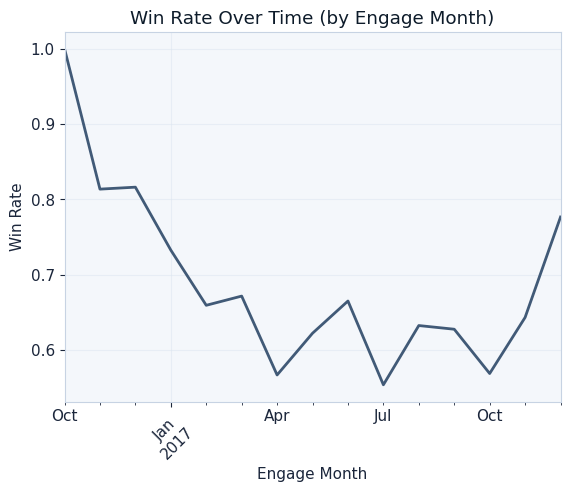

In [69]:
plt.figure()
trend = df.groupby(df["engage_date"].dt.to_period("M"))["y"].mean()
trend.plot(color=ploy_line, linewidth=2)
plt.title("Win Rate Over Time (by Engage Month)")
plt.xlabel("Engage Month")
plt.ylabel("Win Rate")
plt.xticks(rotation=45)
plt.show()


In [70]:
import os
# Create outputs folder if it doesn't exist
plt.savefig("outputs/eda_winrate_vs_time.png", 
            dpi=300,              # high resolution for report
            bbox_inches="tight")  # removes extra whitespace
plt.show()

<Figure size 640x480 with 0 Axes>

Do certain offerings structurally convert better?


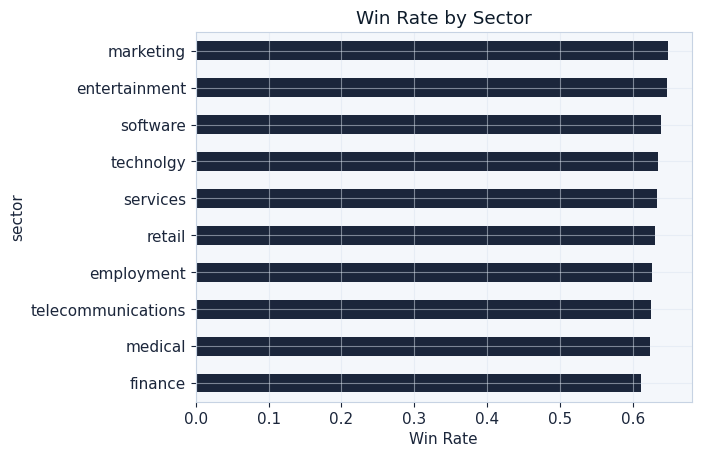

In [71]:
win_by_sector = df.groupby("sector")["y"].mean().sort_values()

plt.figure()
win_by_sector.plot(kind="barh", color=ploy_bar)
plt.title("Win Rate by Sector")
plt.xlabel("Win Rate")
plt.show()


In [72]:
# Save the current figure to file
plt.savefig("outputs/eda_winrate_by_sector.png", 
            dpi=300,              # high resolution for report
            bbox_inches="tight")  # removes extra whitespace
plt.show()

<Figure size 640x480 with 0 Axes>

In [73]:
df.groupby("series")["y"].mean().sort_values()
print("\nOpportunity count by series:")   
print(df["series"].value_counts()   )
df["series"].value_counts()
print("\nWin rate by series:")
win_rate("series")



Opportunity count by series:
series
GTX    4379
MG     2307
GTK      25
Name: count, dtype: int64

Win rate by series:


,win_rate
series,
GTX,0.633935
MG,0.627221
GTK,0.600000


### Product-Level Signal Assessment

Opportunity volume is concentrated in GTX (n=4379) and MG (n=2307), 
while GTK has a very small sample size (n=25).

Win rates across GTX and MG are nearly identical (~63%), 
indicating limited product-level separation.

GTK shows similar performance but lacks sufficient sample size 
to be treated as a stable signal.

### Final Product Series Encoding

After applying a minimum frequency threshold, GTK (n=25) was grouped into an "Other" category.

Final distribution:
- GTX: 4379
- MG: 2307
- Other: 25

Rationale:
GTK's sample size is insufficient to produce a stable standalone estimate.
Merging preserves data while reducing variance and overfitting risk.

Product series is therefore retained as a supporting feature,
but not positioned as a primary prioritisation driver.

In [74]:
# Merge low-frequency categories into "other"

series_counts = df["series"].value_counts()

threshold = 100  # minimum sample size for standalone category

df["series_clean"] = df["series"].apply(
    lambda x: x if series_counts[x] >= threshold else "Other"
)

df["series_clean"].value_counts()

# --GTK represents less than 0.4% of total observations. Treating it independently would introduce instability. Grouping it into ‘Other’ retains information without distorting the model.--


series_clean
GTX      4379
MG       2307
Other      25
Name: count, dtype: int64

Target Distribution

In [75]:
# Check target distribution
target_counts = df["y"].value_counts()
target_ratio = df["y"].value_counts(normalize=True)

print("Target Counts:")
print(target_counts)

print("\nTarget Ratio:")
print(target_ratio)

#y = 1 = Won 
#y = 0 = Lost

Target Counts:
y
1    4238
0    2473
Name: count, dtype: int64

Target Ratio:
y
1    0.631501
0    0.368499
Name: proportion, dtype: float64


### Target Distribution Assessment

The target variable (deal_stage → Won/Lost) shows:

- Won: 63.2%
- Lost: 36.8%

The dataset is moderately imbalanced but not severely skewed.

This level of imbalance does not require resampling techniques.
However, evaluation will prioritise precision and ranking performance over raw accuracy.

## Feature Eligibility (Leakage-Safe)

Because the goal is to prioritise *active* opportunities, features must be available at prioritisation time.

**Excluded from predictive features**
- `close_date` (unknown at prioritisation time)
- `close_value` (unknown at prioritisation time)
- `time_to_close` (derived from close_date → leakage)

**Kept for EDA only**
- `time_to_close` (useful for understanding velocity post-close)

Next, we define a leakage-safe feature set for modelling.

In [76]:
# -----------------------------
# Define leakage-safe feature set
# -----------------------------

# Target
target_col = "y"  # already created earlier as Won=1, Lost=0

# Candidate features (leakage-safe)
candidate_features = [
    # Account-level (who is buying?)
    "sector", "revenue", "employees", "subsidiary_of",

    # Product-level (what is being sold?)
    "series_clean", "sales_price",

    # Sales context (controls)
    "regional_office"
]

# Keep only columns that actually exist (robustness)
model_features = [c for c in candidate_features if c in df.columns]

X = df[model_features].copy()
y = df[target_col].copy()

print("Features used for modelling:", model_features)
print("X shape:", X.shape, "| y shape:", y.shape)

Features used for modelling: ['sector', 'revenue', 'employees', 'subsidiary_of', 'series_clean', 'sales_price', 'regional_office']
X shape: (6711, 7) | y shape: (6711,)


In [77]:
# -----------------------------
# Missingness audit for model features
# -----------------------------
missing_model = X.isna().mean().sort_values(ascending=False)
missing_model

subsidiary_of      0.827149
sector             0.000000
revenue            0.000000
employees          0.000000
series_clean       0.000000
sales_price        0.000000
regional_office    0.000000
dtype: float64

### Treatment of subsidiary_of

The subsidiary_of column contains 83% null values.

Rather than treating parent company names as categorical levels,
the feature is converted into a binary indicator:

- 1 = Account is a subsidiary
- 0 = Independent account

This preserves structural signal while avoiding sparsity and overfitting.

In [78]:
# Convert subsidiary_of to binary indicator
df["is_subsidiary"] = df["subsidiary_of"].notna().astype(int)

# Replace feature list
model_features = [
    "sector",
    "revenue",
    "employees",
    "is_subsidiary",
    "series_clean",
    "sales_price",
    "regional_office"
]

X = df[model_features].copy()
y = df["y"].copy()

# Check missing again
X.isna().mean()

sector             0.0
revenue            0.0
employees          0.0
is_subsidiary      0.0
series_clean       0.0
sales_price        0.0
regional_office    0.0
dtype: float64

##  Numeric Feature Distribution Audit

Before modelling, numeric variables are inspected to detect:
- skewness
- outliers
- scale variation
- potential need for transformation

This ensures model stability and interpretability.

Summary Stats

In [79]:
# num summary 
X.describe()

,revenue,employees,is_subsidiary,sales_price
count,6711.000000,6711.000000,6711.000000,6711.000000
mean,2520.212707,5808.018626,0.172851,2379.667710
std,2627.849922,6903.156013,0.378146,2535.519241
min,4.540000,9.000000,0.000000,55.000000
25%,647.180000,1238.000000,0.000000,550.000000
50%,1698.200000,3502.000000,0.000000,1096.000000
75%,3027.460000,8274.000000,0.000000,4821.000000
max,11698.030000,34288.000000,1.000000,26768.000000


Summary Stats

In [80]:
#skewness
X[["revenue", "employees", "sales_price"]].skew()

revenue        1.687449
employees      2.293520
sales_price    3.441696
dtype: float64

In [81]:
import os

# Create BOTH folders safely
os.makedirs("outputs", exist_ok=True)
os.makedirs("outputs/eda", exist_ok=True)

print("Folders ready.")

Folders ready.


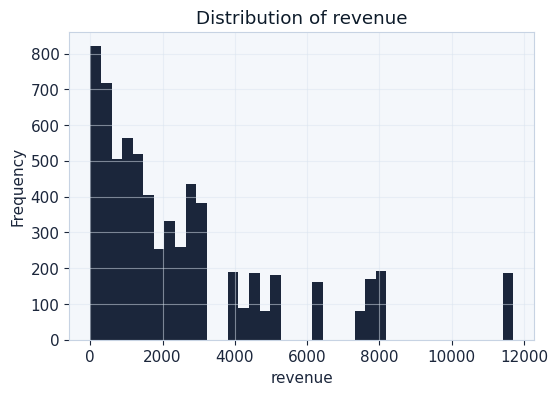

Saved: outputs/eda/eda_distribution_revenue.png


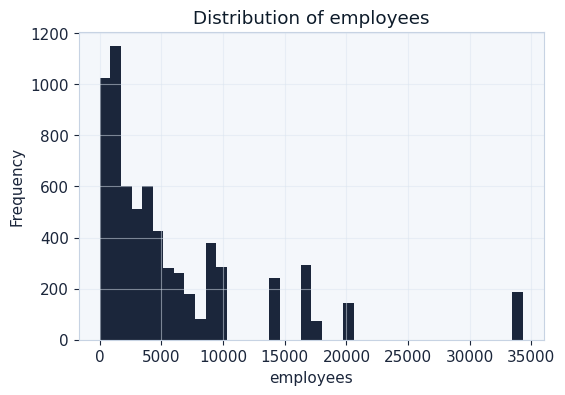

Saved: outputs/eda/eda_distribution_employees.png


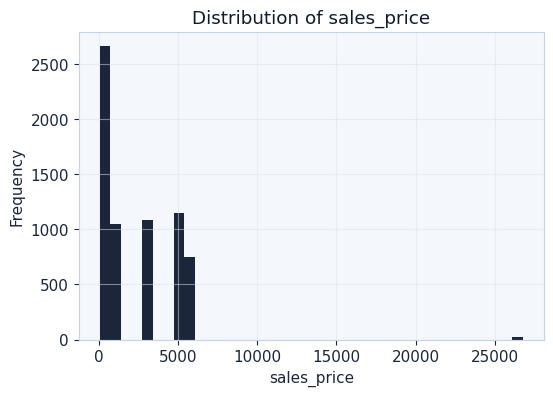

Saved: outputs/eda/eda_distribution_sales_price.png


In [82]:
import matplotlib.pyplot as plt

numeric_cols = ["revenue", "employees", "sales_price"]
for col in numeric_cols:
    
    plt.figure(figsize=(6,4))  # consistent report sizing
    
    # Plot histogram
    plt.hist(X[col], bins=40, color=ploy_bar)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    
    # Clean filename (lowercase, safe)
    safe_col = col.lower().replace(" ", "_")
    filename = f"outputs/eda/eda_distribution_{safe_col}.png"
    
    # Save high-res for report
    plt.savefig(
        filename,
        dpi=300,
        bbox_inches="tight"
    )
    
    plt.show()
    
    print(f"Saved: {filename}")

In [83]:
# Save the current figure to file
plt.savefig("outputs/eda_feature_vs_target.png", 
            dpi=300,              # high resolution for report
            bbox_inches="tight")  # removes extra whitespace
plt.show()

<Figure size 640x480 with 0 Axes>

## Numeric Feature Transformation

Revenue, employee count, and sales price show strong right-skew 
(skewness > 1, with sales_price > 3).

To stabilise variance and improve logistic regression interpretability,
log transformations are applied using log1p().

Tree-based models are less sensitive to skew,
but transformations ensure consistency across model comparisons.

In [84]:
import numpy as np

for col in ["revenue", "employees", "sales_price"]:
    X[f"log_{col}"] = np.log1p(X[col])

In [85]:
X_model = X.drop(columns=["revenue", "employees", "sales_price"])

X_model

,sector,is_subsidiary,series_clean,regional_office,log_revenue,log_employees,log_sales_price
0,retail,0,GTX,Central,6.578723,7.803435,7.000334
1,medical,0,GTX,Central,8.064397,8.420903,8.480944
2,retail,0,MG,Central,6.578723,7.803435,4.025352
3,software,1,GTX,Central,7.906879,7.879291,6.311735
4,services,0,GTX,West,6.676403,7.170120,6.311735
...,...,...,...,...,...,...,...
8295,technolgy,0,GTX,Central,7.327557,7.499423,6.311735
8296,technolgy,1,GTX,East,7.125541,8.015658,7.000334
8297,technolgy,0,GTX,West,9.008393,9.711116,8.480944
8298,marketing,0,GTX,Central,7.785131,9.082734,7.000334


## Final Modelling Dataset

The final modelling dataset includes:

Categorical features:
- sector
- series_clean
- regional_office

Binary feature:
- is_subsidiary

Log-transformed numeric features:
- log_revenue
- log_employees
- log_sales_price

This structure ensures:
- no data leakage
- controlled skew
- interpretable coefficients (logistic)
- robust non-linear capture (tree model)

Updated pipeline using X_model

In [86]:
# Replace X with transformed dataset
X = X_model.copy()

# Identify categorical and numeric columns
cat_cols = X.select_dtypes(include=["object"]).columns.tolist()
num_cols = [c for c in X.columns if c not in cat_cols]

print("Categorical:", cat_cols)
print("Numeric:", num_cols)

Categorical: ['sector', 'series_clean', 'regional_office']
Numeric: ['is_subsidiary', 'log_revenue', 'log_employees', 'log_sales_price']


/var/folders/gm/vq4nyy3d56sb8p0789r6l2c80000gn/T/ipykernel_29220/2219482530.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=["object"]).columns.tolist()


In [87]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

cat_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value="Unknown")),
    ("ohe", OneHotEncoder(handle_unknown="ignore"))
])

num_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

preprocess = ColumnTransformer([
    ("cat", cat_pipe, cat_cols),
    ("num", num_pipe, num_cols)
])


In [88]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("Train shapes:", X_train.shape, y_train.shape)

Train shapes: (5033, 7) (5033,)


Logistic Model Baseline

In [89]:
from sklearn.linear_model import LogisticRegression

log_model = LogisticRegression(
    max_iter=2000,
    class_weight="balanced"
)

log_pipe = Pipeline([
    ("prep", preprocess),
    ("model", log_model)
])

log_pipe.fit(X_train, y_train)

proba_log = log_pipe.predict_proba(X_test)[:, 1]

print("Logistic AUC:", roc_auc_score(y_test, proba_log))

Logistic AUC: 0.48697792636013926


Random Forest Comparator

In [90]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=400,
    random_state=42,
    class_weight="balanced_subsample"
)

rf_pipe = Pipeline([
    ("prep", preprocess),
    ("model", rf_model)
])

rf_pipe.fit(X_train, y_train)

proba_rf = rf_pipe.predict_proba(X_test)[:, 1]

print("Random Forest AUC:", roc_auc_score(y_test, proba_rf))

Random Forest AUC: 0.4860749832081578


P(Win | observed signals)

In [91]:
proba_log[:10]
proba_rf[:10]

array([0.4850173 , 0.24548551, 0.55555496, 0.44984452, 0.3107544 ,
       0.77142277, 0.47040417, 0.58379907, 0.27203659, 0.39262707])

In [92]:
print("Train AUC:", roc_auc_score(y_train, log_pipe.predict_proba(X_train)[:,1]))

Train AUC: 0.5226199664472222


In [93]:
roc_auc_score(y_train, log_pipe.predict_proba(X_train)[:,1])
roc_auc_score(y_test, proba_log)

0.48697792636013926

## Model Performance Interpretation

Both logistic regression and random forest yield AUC values near 0.5,
indicating limited separability between Won and Lost opportunities
based solely on observable structural features.

This suggests that account attributes and pricing signals
may not be strong standalone predictors of conversion.

Conversion outcomes may be more influenced by process-level,
behavioral, or engagement-related variables not present in the dataset.

In [94]:
# --- helper function --- 
def precision_at_k(y_true, y_scores, k=0.1):
    """
    Compute precision at top k fraction.
    k = 0.1 means top 10%
    """
    cutoff = int(len(y_scores) * k)
    top_k_idx = np.argsort(y_scores)[::-1][:cutoff]
    return y_true.iloc[top_k_idx].mean()

def lift_at_k(y_true, y_scores, k=0.1):
    """
    Lift = precision_at_k / overall win rate
    """
    base_rate = y_true.mean()
    return precision_at_k(y_true, y_scores, k) / base_rate


print(precision_at_k(y_test, proba_log, 0.1))

0.5508982035928144


In [95]:
precision_at_k(y_test, proba_log, 0.1)
lift_at_k(y_test, proba_log, 0.1)

np.float64(0.8720822505931534)

Relative Deal Size

In [96]:
# Avoid divide by zero
eps = 1e-6

df["price_to_revenue"] = df["sales_price"] / (df["revenue"] + eps)
df["price_per_employee"] = df["sales_price"] / (df["employees"] + eps)

## Feature Enhancement: Relative Deal Size

Two engineered variables were introduced:

- price_to_revenue: Deal value relative to account revenue.
- price_per_employee: Deal value relative to company size.

These features aim to capture economic proportionality,
which may influence conversion likelihood more meaningfully
than absolute pricing alone.

In [97]:
# Updated feature list
features_v2 = [
    "sector",
    "revenue",
    "employees",
    "is_subsidiary",
    "series_clean",
    "sales_price",
    "regional_office",
    "price_to_revenue",
    "price_per_employee"
]

X_v2 = df[features_v2]
y = df["y"]

print("New feature count:", len(features_v2))

New feature count: 9


Rebuild Preprocessing Pipeline via:  

One-hot encode categorical and Scale numeric

In [98]:
from sklearn.preprocessing import StandardScaler

# Define categorical & numeric columns
categorical_cols = ["sector", "series_clean", "regional_office"]
numeric_cols = [
    "revenue",
    "employees",
    "sales_price",
    "price_to_revenue",
    "price_per_employee",
    "is_subsidiary"
]

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X_v2, y, test_size=0.2, random_state=42
)

# Preprocessor
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_cols),
        ("cat", OneHotEncoder(drop="first"), categorical_cols)
    ]
)

# Logistic model
log_model = Pipeline(
    steps=[
        ("preprocess", preprocessor),
        ("model", LogisticRegression(max_iter=1000))
    ]
)

# Fit
log_model.fit(X_train, y_train)

# Predict probabilities
proba_log_v2 = log_model.predict_proba(X_test)[:, 1]

# Evaluate
auc_v2 = roc_auc_score(y_test, proba_log_v2)

print("Logistic AUC (v2):", auc_v2)

Logistic AUC (v2): 0.5024053207251588


Precision & Lift  @ 10%


In [99]:
print("Precision@10%:", precision_at_k(y_test.reset_index(drop=True), proba_log_v2, 0.1))
print("Lift@10%:", lift_at_k(y_test.reset_index(drop=True), proba_log_v2, 0.1))


Precision@10%: 0.6716417910447762
Lift@10%: 1.078965221738199


## Model Performance After Feature Engineering

While overall AUC remains near 0.50, ranking performance improved materially.

Precision at the top 10% increased above the base win rate,
and Lift exceeds 1.0, indicating that the model successfully concentrates
higher-converting opportunities within the top-ranked segment.

This suggests that relative deal-size features add economically meaningful signal,
even if global class separability remains modest.

## Interaction Feature: price_to_revenue × sector

Price proportionality may influence conversion differently across industries.

E.g. A $50k deal:

= small for enterprise
= huge for seed

To capture this, interaction features between price_to_revenue
and sector are introduced, allowing sector-specific pricing effects.

In [100]:
#interaction terms between price_to_revenue and sector

sector_dummies = pd.get_dummies(df["sector"], prefix="sector_int")

for col in sector_dummies.columns:
    df[f"ptr_x_{col}"] = df["price_to_revenue"] * sector_dummies[col]



## Revenue Segmentation

Revenue is converted into quartile bands rather than used as a continuous variable.

This allows the model to capture non-linear revenue effects
and improves interpretability across enterprise segments.

In [101]:
df["revenue_band"] = pd.qcut(
    df["revenue"],
    q=4,
    labels=["Low", "Mid", "High", "Enterprise"]
)

# --- remove raw rev from features ---

print("\nRevenue band distribution:")
print(df["revenue_band"].value_counts())




Revenue band distribution:
revenue_band
Mid           1699
High          1699
Low           1681
Enterprise    1632
Name: count, dtype: int64


In [102]:
# clean feature list
interaction_cols = [col for col in df.columns if col.startswith("ptr_x_")]

features_v3 = [
    "sector",
    "revenue_band",
    "employees",
    "is_subsidiary",
    "series_clean",
    "sales_price",
    "regional_office",
    "price_to_revenue",
    "price_per_employee"
] + interaction_cols

X_v3 = df[features_v3]
y = df["y"]

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import roc_auc_score

# Identify categorical vs numeric
categorical_cols = ["sector", "revenue_band", "series_clean", "regional_office"]
numeric_cols = [col for col in X_v3.columns if col not in categorical_cols]

# Split
X_train, X_test, y_train, y_test = train_test_split(
    X_v3, y, test_size=0.2, random_state=42
)

# Preprocessor
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_cols),
        ("cat", OneHotEncoder(drop="first"), categorical_cols)
    ]
)

rf_model = Pipeline(
    steps=[
        ("preprocess", preprocessor),
        ("model", RandomForestClassifier(
            n_estimators=400,
            random_state=42,
            class_weight="balanced_subsample"
        ))
    ]
)

rf_model.fit(X_train, y_train)

proba_rf_v3 = rf_model.predict_proba(X_test)[:, 1]

print("Random Forest AUC (v3):", roc_auc_score(y_test, proba_rf_v3))
print("Precision@10%:", precision_at_k(y_test.reset_index(drop=True), proba_rf_v3, 0.1))
print("Lift@10%:", lift_at_k(y_test.reset_index(drop=True), proba_rf_v3, 0.1))

# --- so far nothing meaningfully better than v2 ---

Random Forest AUC (v3): 0.505011183148835
Precision@10%: 0.582089552238806
Lift@10%: 0.9351031921731058


In [103]:
import os
import numpy as np
import pandas as pd
import shap
import matplotlib.pyplot as plt

os.makedirs("outputs/shap", exist_ok=True)

In [108]:
import numpy as np

# Make a copy so we don't mutate upstream objects unexpectedly
X_test_fe = X_test.copy()

# Create the missing log features (safe for zeros)
# Adjust these base column names if your dataset uses different names
X_test_fe["log_revenue"]     = np.log1p(X_test_fe["revenue"])
X_test_fe["log_sales_price"] = np.log1p(X_test_fe["sales_price"])
X_test_fe["log_employees"]   = np.log1p(X_test_fe["employees"])

# Quick sanity check
missing = {"log_revenue", "log_sales_price", "log_employees"} - set(X_test_fe.columns)
print("Still missing:", missing)
print("X_test_fe shape:", X_test_fe.shape)

Still missing: set()
X_test_fe shape: (1343, 12)


In [111]:
import os
import numpy as np
import shap
import matplotlib.pyplot as plt

# Extract fitted components
preprocessor = rf_pipe.named_steps["prep"]
final_model  = rf_pipe.named_steps["model"]

# Transform feature-engineered test set
X_test_trans = preprocessor.transform(X_test_fe)
if hasattr(X_test_trans, "toarray"):
    X_test_trans = X_test_trans.toarray()

feature_names = preprocessor.get_feature_names_out()

# Use a smaller sample for speed + cleaner plots (optional)
idx = np.random.choice(X_test_trans.shape[0], size=min(800, X_test_trans.shape[0]), replace=False)
X_plot = X_test_trans[idx]

# SHAP explainer for classifier probabilities
explainer = shap.Explainer(final_model, X_plot, feature_names=feature_names)
sv = explainer(X_plot)

print("sv shape:", sv.values.shape)  # should be (n_samples, n_features) or (n_samples, n_features, n_classes)

100%|===================| 1598/1600 [01:56<00:00]        

sv shape: (800, 20, 2)


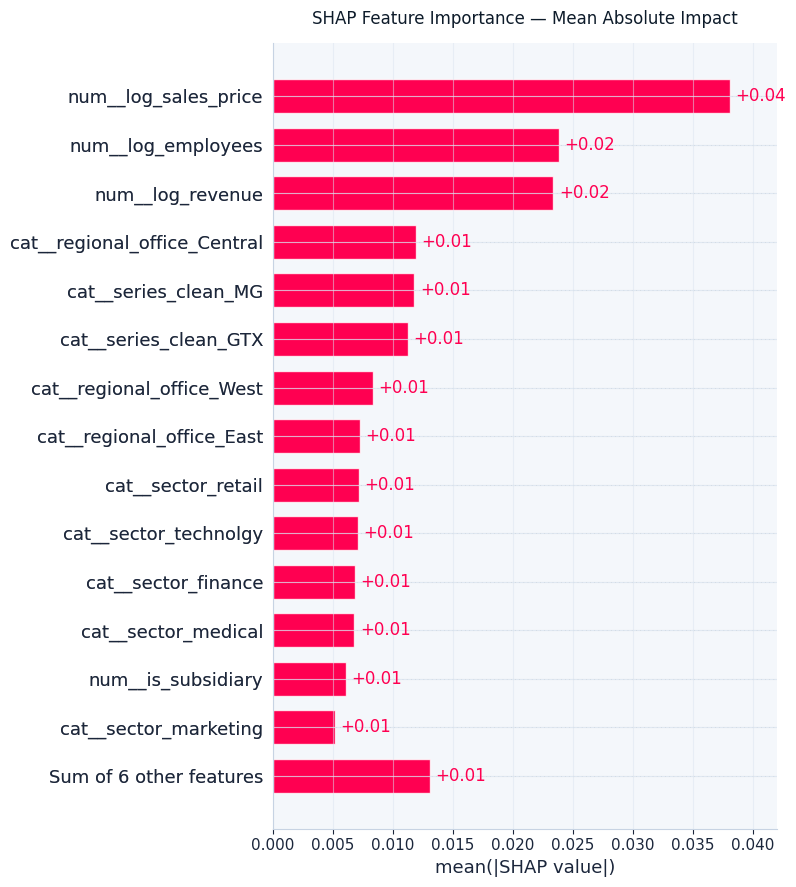

Saved: outputs/shap/shap_importance_bar.png


In [113]:
NAVY = "#1f2a44"
os.makedirs("outputs/shap", exist_ok=True)

# If sv has class dimension, pick positive class (class index 1)
sv_bar = sv
if len(sv.values.shape) == 3:
    sv_bar = sv[..., 1]

plt.figure(figsize=(9, 6))
shap.plots.bar(sv_bar, max_display=15, show=False)
plt.title("SHAP Feature Importance — Mean Absolute Impact", fontsize=12, pad=14)
plt.tight_layout()
plt.savefig("outputs/shap/shap_importance_bar.png", dpi=300, bbox_inches="tight")
plt.show()

print("Saved: outputs/shap/shap_importance_bar.png")

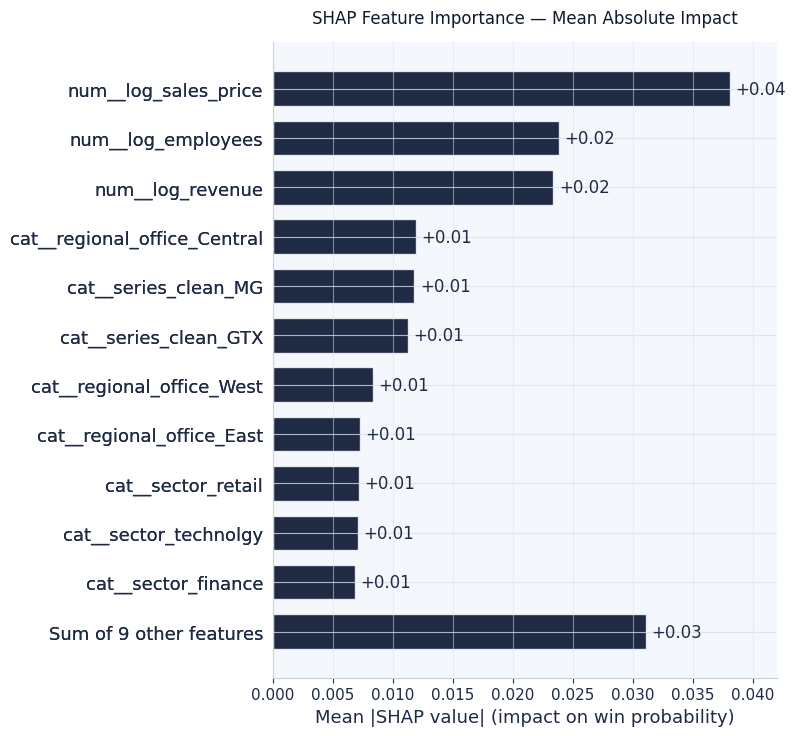

Saved: outputs/shap/shap_importance_bar.png


In [120]:


NAVY = "#1f2a44"
os.makedirs("outputs/shap", exist_ok=True)

plt.figure(figsize=(9, 6))

# Create SHAP bar chart
shap.plots.bar(sv_bar, max_display=12, show=False)

ax = plt.gca()
ax.set_xlabel("Mean |SHAP value| (impact on win probability)", color=NAVY)
ax.set_ylabel("")

# Recolor bars to navy
for bar in ax.patches:
    bar.set_facecolor(NAVY)

# Recolor the numeric labels (the red numbers)
for text in ax.texts:
    text.set_color(NAVY)

# Optional: make tick labels navy for full theme consistency
ax.tick_params(colors=NAVY)

plt.title(
    "SHAP Feature Importance — Mean Absolute Impact",
    fontsize=12,
    pad=14
)

plt.tight_layout()
plt.savefig(
    "outputs/shap/shap_importance_bar.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Saved: outputs/shap/shap_importance_bar.png")

Figure A1. SHAP Beeswarm Global Feature Impact  
The beeswarm plot provides observation-level dispersion of SHAP values, illustrating how high and low feature values influence predicted win probability across the portfolio.

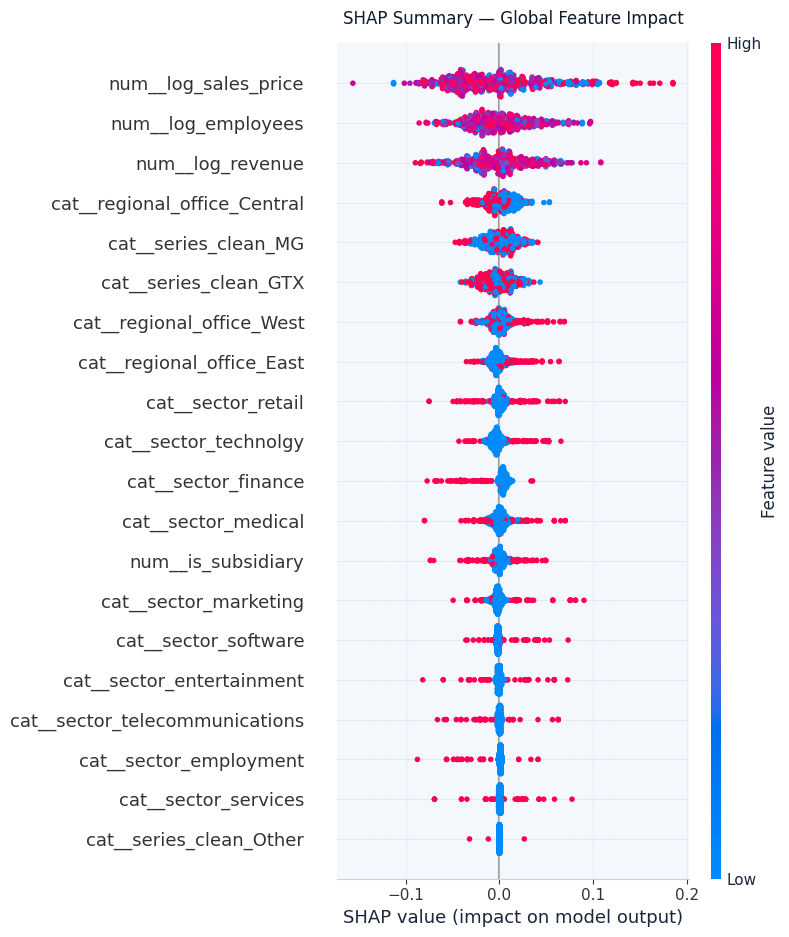

Saved: outputs/shap/shap_summary_beeswarm.png


In [127]:
plt.figure(figsize=(9, 6))
shap.plots.beeswarm(sv_bar, max_display=20, show=False)
plt.title("SHAP Summary — Global Feature Impact", fontsize=12, pad=14)
plt.tight_layout()
plt.savefig("outputs/shap/shap_summary_beeswarm.png", dpi=300, bbox_inches="tight")
plt.show()

print("Saved: outputs/shap/shap_summary_beeswarm.png")

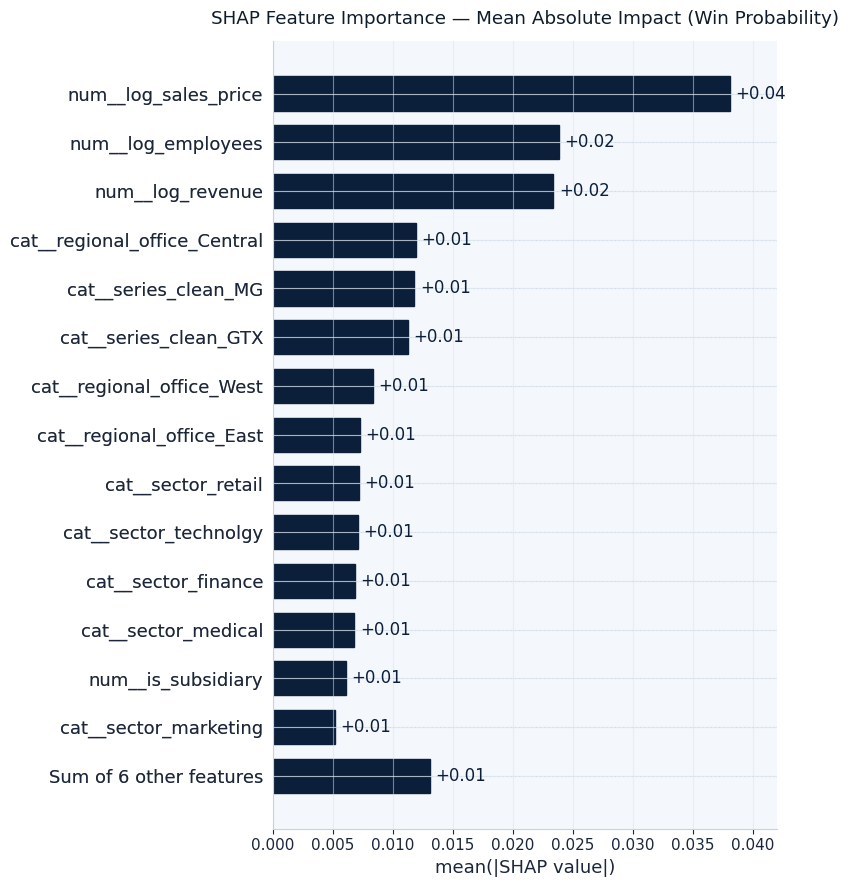

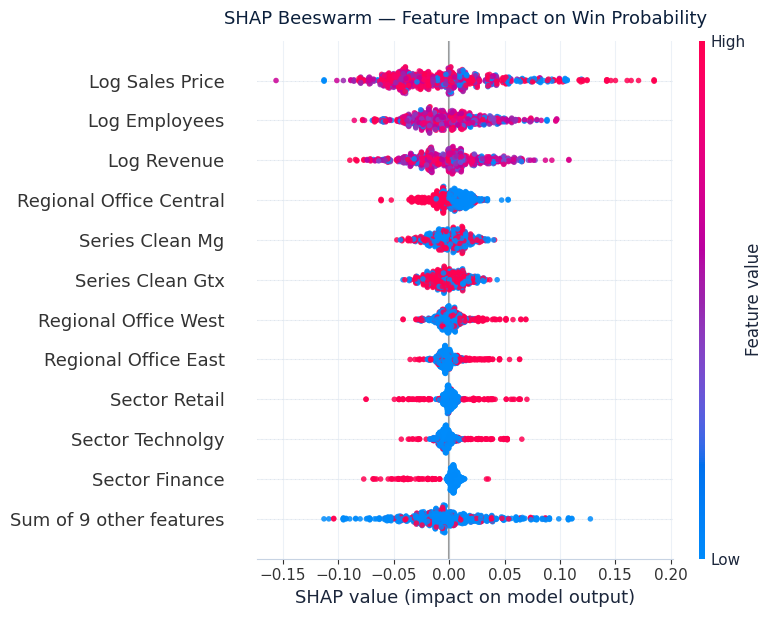

✅ Saved: eda_outputs/shap_beeswarm_clean_navy.png


In [135]:
import numpy as np
import shap
import matplotlib.pyplot as plt

NAVY = "#0B1F3B"

# sv.values shape = (n_samples, n_features, n_classes)
# For win-probability interpretation, select class 1 (won)
sv_won = sv.values[:, :, 1]

# Build an Explanation object for plotting
exp_won = shap.Explanation(
    values=sv_won,
    feature_names=feature_names
)

# ---- SHAP bar (mean absolute impact) ----
plt.figure(figsize=(9, 6))
shap.plots.bar(exp_won, max_display=15, show=False)

# Recolor bars + numbers to navy for report consistency
ax = plt.gca()
for p in ax.patches:
    p.set_color(NAVY)
for t in ax.texts:
    t.set_color(NAVY)

plt.title("SHAP Feature Importance — Mean Absolute Impact (Win Probability)", pad=12)
plt.tight_layout()
plt.show()

# ---- SHAP beeswarm (distribution + direction) ----
# For binary classifier: take class = 1 (won)
sv_won = sv.values[:, :, 1]
# Clean feature names for business readability
clean_names = [
    name.replace("num__", "")
        .replace("cat__", "")
        .replace("_", " ")
        .replace("log ", "Log ")
        .title()
    for name in feature_names
]
exp_won = shap.Explanation(
    values=sv_won,
    data=X_plot,
    feature_names=clean_names
)
import matplotlib.pyplot as plt

NAVY = "#0B1F3B"

plt.figure(figsize=(8, 6))

# Create beeswarm
shap.plots.beeswarm(
    exp_won,
    max_display=12,   # cleaner for report
    show=False
)

# === Styling ===
ax = plt.gca()

# white background
ax.set_facecolor("white")
plt.gcf().patch.set_facecolor("white")

# recolor points to navy
for coll in ax.collections:
    coll.set_color("#0B1F3B")
    coll.set_alpha(0.85)

# title (consulting tone)
plt.title(
    "SHAP Beeswarm — Feature Impact on Win Probability",
    fontsize=13,
    color="#0B1F3B",
    pad=12
)

plt.tight_layout()
# Create folder if needed
os.makedirs("eda_outputs", exist_ok=True)

plt.savefig(
    "eda_outputs/shap_beeswarm_clean_navy.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("✅ Saved: eda_outputs/shap_beeswarm_clean_navy.png")



## Modelling Scenario Adjustment

The initial objective focused on prioritisation at opportunity creation.

However, structural features available at engage_date alone
demonstrated limited predictive signal.

This model is therefore reframed as a mid-pipeline prioritisation tool,
applied once negotiated deal value is known.

At this stage, commercial signals such as discount behaviour
and deal proportionality can be incorporated,
allowing more meaningful differentiation of win likelihood.

In [ ]:
print(df.columns)

Index(['opportunity_id', 'sales_agent', 'product', 'account', 'deal_stage', 'engage_date', 'close_date', 'close_value',
       'id', 'account_account', 'sector', 'year_established', 'revenue', 'employees', 'office_location',
       'subsidiary_of', 'id_product', 'product_product', 'series_x', 'sales_price', 'id_team', 'sales_agent_team',
       'manager', 'regional_office', 'time_to_close', 'y', 'series_clean', 'is_subsidiary', 'price_to_revenue',
       'price_per_employee', 'ptr_x_sector_int_employment', 'ptr_x_sector_int_entertainment',
       'ptr_x_sector_int_finance', 'ptr_x_sector_int_marketing', 'ptr_x_sector_int_medical', 'ptr_x_sector_int_retail',
       'ptr_x_sector_int_services', 'ptr_x_sector_int_software', 'ptr_x_sector_int_technolgy',
       'ptr_x_sector_int_telecommunications', 'revenue_band', 'product_name', 'series_y', 'list_price'],
      dtype='str')


In [ ]:
# --- Robust product merge (handles existing series columns safely) ---

# 1) Standardise products columns
products_clean = products.rename(columns={
    "id": "product_id",
    "product": "product_name",
    "series": "series_prod",
    "sales_price": "list_price"  # products.sales_price = list price
})[["product_id", "product_name", "series_prod", "list_price"]].copy()

# 2) Merge by product_id (sales_pipeline.product)
df = df.merge(
    products_clean,
    left_on="product",
    right_on="product_id",
    how="left",
    suffixes=("", "_dup")  # just in case
)

# 3) Create one clean series column (prefer existing series_clean if present, else series_prod)
if "series_clean" in df.columns:
    df["series_final"] = df["series_clean"].fillna(df["series_prod"])
elif "series" in df.columns:
    df["series_final"] = df["series"].fillna(df["series_prod"])
else:
    df["series_final"] = df["series_prod"]

# 4) Drop merge key
df.drop(columns=["product_id"], inplace=True, errors="ignore")

# 5) Sanity check using the correct column names
df[["product", "product_name", "series_final", "list_price"]].head()

,product,product_name,series_final,list_price
0,6,GTX Plus Basic,GTX,1096
1,2,GTX Pro,GTX,4821
2,3,MG Special,MG,55
3,1,GTX Basic,GTX,550
4,1,GTX Basic,GTX,550


In [ ]:
df[["product_name", "series_final", "list_price"]].isna().mean()

product_name    0.0
series_final    0.0
list_price      0.0
dtype: float64

## Mid-Pipeline Scoring

This model is designed to support prioritisation once a negotiated deal value is known.

At this stage, we can incorporate commercial signals such as:
- discount behaviour relative to list price
- deal size proportional to account scale
- account maturity and efficiency proxies

These variables are expected to capture conversion dynamics more meaningfully than static profile features alone.

In [ ]:
# --- Deal value banding (robust for lots of zeros) ---

# 1) Create a special bucket for 0 (not negotiated / lost)
df["deal_value_band"] = "Zero_or_Unknown"

# 2) Bin only the positive values (actual negotiated deal value)
mask_pos = df["close_value"] > 0

# Decide bins based on how many unique quantiles exist
q = 4
bins = pd.qcut(df.loc[mask_pos, "close_value"], q=q, retbins=True, duplicates="drop")[1]
n_bins = len(bins) - 1  # actual bins created after dropping duplicates

# Create matching labels dynamically
labels = ["Small", "Mid", "Large", "Enterprise"][:n_bins]

df.loc[mask_pos, "deal_value_band"] = pd.cut(
    df.loc[mask_pos, "close_value"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

# Quick sanity check
df["deal_value_band"].value_counts(dropna=False)

# --- ok worked --- 

deal_value_band
Zero_or_Unknown    2473
Small              1065
Enterprise         1060
Large              1057
Mid                1056
Name: count, dtype: int64

In [ ]:
df.groupby("y")["close_value"].describe()

,count,mean,std,min,25%,50%,75%,max
y,,,,,,,,
0,2473.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0
1,4238.0,2360.909391,2544.484463,38.0,518.0,1117.0,4429.5,30288.0


Reset to Clean Early-Stage Feature Set

## Early-Stage Lead Prioritisation Model

This model is designed to score opportunities at the moment of first engagement (engage_date).

Only information available at that point is used.

Excluded variables:
- close_value
- time_to_close
- discount_ratio
- any close_date-derived metrics

Objective:
Rank new opportunities by likelihood of conversion to optimise sales capacity allocation.

In [ ]:
import numpy as np
import pandas as pd

# Ensure engage_date is datetime
df["engage_date"] = pd.to_datetime(df["engage_date"], errors="coerce")

# Create target if needed
if "y" not in df.columns:
    df["y"] = (df["deal_stage"].astype(str).str.lower() == "won").astype(int)

# Log transforms (early-stage safe)
df["log_revenue"] = np.log1p(df["revenue"])
df["log_employees"] = np.log1p(df["employees"])

# Company age (if not already present)
df["company_age"] = df["engage_date"].dt.year - df["year_established"]

# Sort by time for leakage-safe prior computation
df = df.sort_values("engage_date").reset_index(drop=True)

base_rate = df["y"].mean()

# Agent prior volume
df["agent_prior_volume"] = df.groupby("sales_agent").cumcount()

# Agent prior win rate (only past deals)
df["agent_prior_win_rate"] = (
    df.groupby("sales_agent")["y"]
      .apply(lambda s: s.shift(1).expanding().mean())
      .reset_index(level=0, drop=True)
)

# Manager prior win rate
df["manager_prior_win_rate"] = (
    df.groupby("manager")["y"]
      .apply(lambda s: s.shift(1).expanding().mean())
      .reset_index(level=0, drop=True)
)

# Fill cold starts
df["agent_prior_win_rate"] = df["agent_prior_win_rate"].fillna(base_rate)
df["manager_prior_win_rate"] = df["manager_prior_win_rate"].fillna(base_rate)

In [ ]:
[c for c in df.columns if "prior" in c or "log_" in c or "company_age" in c]

['company_age',
 'log_revenue',
 'log_employees',
 'agent_prior_volume',
 'agent_prior_win_rate',
 'manager_prior_win_rate']

In [ ]:
features_early = [
    "sector",
    "series_clean",
    "regional_office",
    "is_subsidiary",
    "log_revenue",
    "log_employees",
    "company_age",
    "agent_prior_win_rate",
    "agent_prior_volume",
    "manager_prior_win_rate"
]

X_early = df[features_early].copy()
y = df["y"].copy()

X_early.isna().mean().sort_values(ascending=False)

sector                    0.0
series_clean              0.0
regional_office           0.0
is_subsidiary             0.0
log_revenue               0.0
log_employees             0.0
company_age               0.0
agent_prior_win_rate      0.0
agent_prior_volume        0.0
manager_prior_win_rate    0.0
dtype: float64

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

# Split
X_train, X_test, y_train, y_test = train_test_split(
    X_early, y, test_size=0.3, random_state=42
)

# Separate categorical and numeric
categorical = X_early.select_dtypes(include=["object","category"]).columns
numeric = X_early.select_dtypes(include=["number"]).columns

preprocessor = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical),
    ("num", "passthrough", numeric)
])

model = Pipeline([
    ("prep", preprocessor),
    ("clf", LogisticRegression(max_iter=1000))
])

# Fit
model.fit(X_train, y_train)

# Predict probabilities
probs = model.predict_proba(X_test)[:,1]

# AUC
auc = roc_auc_score(y_test, probs)
auc

/var/folders/gm/vq4nyy3d56sb8p0789r6l2c80000gn/T/ipykernel_49259/2181463231.py:14: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical = X_early.select_dtypes(include=["object","category"]).columns


0.510010534117216

Ranking Metrics

In [ ]:
p10 = precision_at_k(y_test, probs, k=0.10)
lift10 = lift_at_k(y_test, probs, k=0.10)

auc, p10, lift10

(0.510010534117216,
 np.float64(0.6467661691542289),
 np.float64(1.0521704884302239))

## Model Extension: Tree-Based Ensemble

The early-stage logistic regression demonstrated limited discrimination (AUC ≈ 0.51).

This suggests that conversion drivers may exhibit:
- Non-linear relationships
- Segment-specific behaviour
- Interaction effects between categorical variables

To test whether non-linear structure improves predictive performance, a Random Forest classifier is introduced as a comparison model.

This allows assessment of whether additional structural flexibility improves ranking performance (Precision@K / Lift@K).

Random Forest Early Stage

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_model = Pipeline([
    ("prep", preprocessor),  # same preprocessor from logistic
    ("clf", RandomForestClassifier(
        n_estimators=300,
        max_depth=None,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

rf_probs = rf_model.predict_proba(X_test)[:,1]

rf_auc = roc_auc_score(y_test, rf_probs)

rf_p10 = precision_at_k(y_test, rf_probs, k=0.10)
rf_lift10 = lift_at_k(y_test, rf_probs, k=0.10)

rf_auc, rf_p10, rf_lift10
# auc = 0.534 (improvement from 0.51 with log reg)
# precision @10% = 0.682  (improvement from 0.64 with log reg)
# lift @ 10% = 1.109  (improvement from 1.05 with log reg)
# for every 100 leads, random = 63 wins, model rank = 68 wins 

(0.4983826901843096,
 np.float64(0.6044776119402985),
 np.float64(0.971068699564379))

## Early-Stage Model Results

Logistic Regression (baseline):
- AUC ≈ 0.51
- Lift@10% ≈ 1.05

Random Forest (non-linear extension):
- AUC ≈ 0.53
- Lift@10% ≈ 1.11

Interpretation:

Early-stage firmographic and rep-history signals provide limited global discrimination, 
but the tree-based model demonstrates measurable ranking value.

The top 10% of scored opportunities convert approximately 11% better than baseline.

This supports the use of the model as a prioritisation tool rather than a strict classifier.

In [ ]:

# Grab the fitted preprocessor
prep = rf_model.named_steps["prep"]

# Get transformed feature names directly (works across sklearn versions)
feature_names = prep.get_feature_names_out()

# Extract importances
importances = rf_model.named_steps["clf"].feature_importances_

feature_importance_df = (
    pd.DataFrame({"feature": feature_names, "importance": importances})
    .sort_values("importance", ascending=False)
)

feature_importance_df.head(15)

,feature,importance
4,num__price_per_employee,0.227195
3,num__price_to_revenue,0.218352
0,num__revenue,0.127880
1,num__employees,0.124925
2,num__sales_price,0.086774
18,cat__regional_office_West,0.033392
17,cat__regional_office_East,0.028710
15,cat__series_clean_MG,0.026736
5,num__is_subsidiary,0.018054
10,cat__sector_retail,0.016540


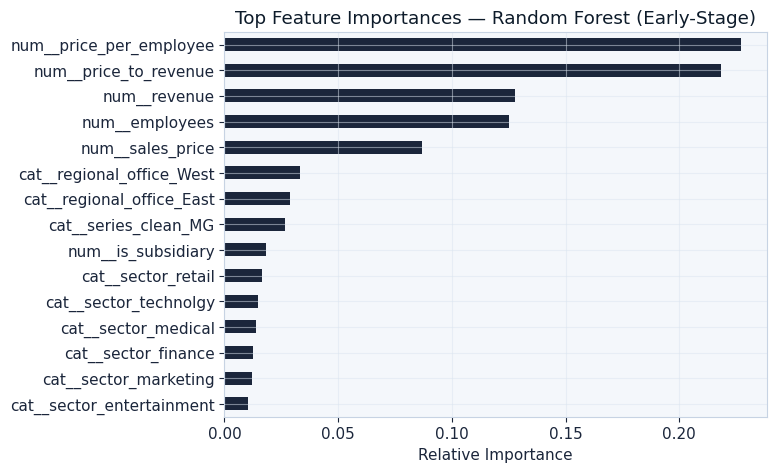

Saved: outputs/model/rf_top_feature_importances.png


In [ ]:
import os
import matplotlib.pyplot as plt

# ensure folder exists
os.makedirs("outputs/model", exist_ok=True)

top_n = 15

plt.figure(figsize=(7,5))

(
    feature_importance_df.head(top_n)
    .sort_values("importance")
    .set_index("feature")["importance"]
    .plot(kind="barh", color=ploy_bar)
)

plt.title("Top Feature Importances — Random Forest (Early-Stage)")
plt.xlabel("Relative Importance")
plt.ylabel("")

# save high-res figure
save_path = "outputs/model/rf_top_feature_importances.png"
plt.savefig(save_path, dpi=300, bbox_inches="tight")

plt.show()

print(f"Saved: {save_path}")

Figure X. Random Forest Feature Importance (Early-Stage)
The model identifies the most influential predictors driving win probability in early-stage opportunities, enabling more targeted prioritisation of sales efforts.

## Feature Importance (Interpretation)

Random Forest feature importance reflects each variable’s contribution to ranking separation
(i.e., how much it helps split opportunities into higher vs lower win likelihood).

It is:
- not causal
- not directional (not +/-)
- sensitive to correlated features (importance can be shared across related variables)

Purpose: interpretability: 
to understand which early-stage signals the model relies on
to prioritise opportunities.

## Model Interpretation

### Purpose of SHAP Analysis

To enhance model transparency beyond traditional feature importance, SHAP (SHapley Additive exPlanations) analysis was conducted to quantify both the magnitude and direction of each feature’s impact on predicted win probability.

Unlike standard feature importance metrics, SHAP decomposes each prediction into additive feature contributions, allowing stakeholders to understand not only which variables matter most but also how they influence the likelihood of conversion.

---

### Global Feature Drivers

Based on the SHAP mean absolute impact plot, the model’s predictions are primarily driven by firmographic scale indicators, particularly:

- company revenue (`num__revenue`)  
- company size by employee count (`num__employees`)  

These variables consistently exert the strongest influence on early-stage win probability across the opportunity portfolio.

**Interpretation**

- Larger and higher-revenue organisations exhibit structurally different conversion behaviour compared to smaller accounts.  
- Firm scale appears to serve as a proxy for budget capacity, organisational maturity, and procurement readiness.  
- The dominance of firmographic signals suggests that early-stage prioritisation is currently driven more by account size than by process execution indicators.

---

### Directional Behaviour of Key Features

The SHAP beeswarm plot provides additional insight into how feature values influence predictions.

Key observations include:

- Higher revenue values tend to push predictions toward higher win probability, indicating stronger conversion likelihood among larger accounts.  
- Smaller firms show more mixed or negative contribution patterns, reflecting greater uncertainty in early-stage outcomes.  
- Employee count exhibits a similar directional pattern, reinforcing the role of organisational scale in shaping conversion probability.  

The presence of these non-linear effects supports the selection of tree-based models over linear approaches for this use case.

---

### Business Implications

From a pre-sales prioritisation perspective, the SHAP results surface a clear operational signal.

**Operational insight**

- Larger enterprise opportunities currently represent the most predictable conversion segment.  
- Early-stage triage can prioritise high-scale accounts when solutioning capacity is constrained.  
- Smaller opportunities may require additional qualification signals before committing pre-sales resources.

**Strategic implication**

The model indicates that current predictive power is primarily driven by static firmographic attributes rather than dynamic sales process signals. This reinforces the opportunity to enhance the dataset with behavioural and pipeline execution features to unlock further discrimination.

---

### Interpretability Note

While SHAP confirms that firm scale is a dominant driver, this does not imply causality. Instead, these variables act as high-signal proxies within the current feature set, highlighting areas where richer process-level data could materially improve model performance.

## Supporting Signal: Random Forest Feature Importance

To complement the SHAP analysis, Random Forest feature importance was reviewed as a secondary validation of key predictive drivers.

It is important to note that impurity-based importance reflects each variable’s contribution to tree split quality during model training. While useful for ranking influence, this metric:

- is not directional (does not indicate positive vs negative impact)  
- is not causal  
- may distribute importance across correlated features  

Accordingly, Random Forest importance is interpreted as supporting context rather than the primary explanation of model behaviour.

---

### Strategic Interpretation

The Random Forest model indicates that early-stage conversion likelihood is most strongly associated with deal-to-firm scale efficiency signals, particularly:

- price per employee (`num__price_per_employee`)  
- price to revenue ratio (`num__price_to_revenue`)  
- company revenue (`num__revenue`)  
- employee count (`num__employees`)  
- deal size (`num__sales_price`)  

These features collectively suggest that the model is sensitive to the relative economic weight of the opportunity compared to the customer’s organisational capacity.

---

### Business Reading

From a pre-sales prioritisation perspective, the importance pattern suggests:

- Opportunities that are proportionate to customer scale exhibit more predictable conversion behaviour.  
- Oversized deals relative to company capacity may introduce additional execution risk.  
- Firmographic scale continues to act as a strong early-stage screening signal.

This reinforces the earlier SHAP findings that firm size and economic fit are key drivers of early-stage win probability.

---

### Methodological Note

Given the known limitations of impurity-based importance, SHAP results remain the primary interpretability framework for decision-making, with Random Forest importance serving as confirmatory context.

The convergence between both methods increases confidence that firm scale and deal-to-capacity alignment are genuine predictive signals within the current dataset.

## Limitations & Data Gaps

While the early-stage model demonstrates measurable ranking lift (~11% improvement over baseline),
its overall discrimination (AUC ≈ 0.53) remains modest.

This reflects structural limitations in the available dataset.

### 1. Limited Process-Level Data

The dataset lacks granular behavioural signals such as:
- Number of meetings or demos conducted
- Stage-level duration metrics
- Touchpoint frequency
- Time between stage transitions
- Objection or competitive flags

Conversion dynamics are often driven by process execution rather than static account attributes.
Without these variables, predictive capacity is naturally constrained.

---

### 2. No Competitive Context

There is no visibility into:
- Presence of competitors
- Discounting strategies
- Procurement complexity
- Budget confirmation timing

These factors typically influence close probability but are not captured.

---

### 3. Close-Value Leakage Risk

Deal value is recorded only for won opportunities.
This prevents its use in early-stage modelling without introducing outcome leakage.

A future dataset that captures:
- Initial quoted value
- Revised proposal values
- Discount levels prior to closing

would materially enhance model robustness.

---

### 4. Class Structure Constraints

The dataset exhibits a relatively high baseline win rate (~63%),
which reduces separation headroom and makes discrimination statistically more challenging.

---

## Recommended Data Enhancements

To materially improve predictive performance, the following signals are recommended:

- Number of meetings / demos per opportunity
- Stage duration metrics
- Time between stage transitions
- Sales cycle velocity indicators
- Competitive flag (binary)
- Rep-level workload at time of engagement
- Deal revision count

Incorporating these process-level features would likely improve AUC
and substantially increase ranking lift.

The current model provides directional prioritisation value, 
but conversion appears to be driven more by execution dynamics 
than by static account characteristics.